### Ändra arbetskatalog

In [1]:
import os

# Byter arbetskatalog från notebooks till projektroten om det behövs
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

# Kontrollerar att Python arbetar från rätt katalog
print("Arbetskatalog:", os.getcwd())

Arbetskatalog: c:\Users\Speldator\Desktop\data-science-group-project


### Importera paket och egna moduler

In [2]:
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Projektets egna moduler
from src.data_split import load_cleaned_data, get_splits
from src.preprocessing import split_features_target, build_preprocessor
from src.random_forest import train_random_forest, get_feature_importances
from src.prediction import predict_probabilities
from src.evaluation import evaluate_top_share, plot_roc_curve, plot_confusion_matrix
from src.experiment_logger import log_experiment, save_plot, get_leaderboard

### Ladda data och kronologiska splits

In [3]:
# Läser in städad data från data/processed/
df = load_cleaned_data()

# Hämtar de kronologiska uppdelningarna
splits = get_splits(df)
train = splits["train_val"]
val = splits["val"]

print("Träningsdata (train_val):", train.shape)
print("Valideringsdata (val):", val.shape)

2026-10-15 11:22:35 [INFO] src.data_split: Läser in städad data från data\processed\hotel_bookings_cleaned.csv
2026-10-15 11:22:36 [INFO] src.data_split: Split vid 2016-07-01: 40414 träning (avbokade 0.308), 11643 utvärdering (avbokade 0.353)
2026-10-15 11:22:36 [INFO] src.data_split: Split vid 2016-10-01: 55393 träning (avbokade 0.321), 14879 utvärdering (avbokade 0.396)
Träningsdata (train_val): (40414, 34)
Valideringsdata (val): (11643, 34)


### Huvudmodell (MED `deposit_type`)

In [4]:
# 1. Separera X och y för träning och validering
X_train_full, y_train = split_features_target(train, include_deposit_type=True)
X_val_full, y_val = split_features_target(val, include_deposit_type=True)

# 2. Skapa preprocessor och transformera
# Vi kör fit_transform på träning och bara transform på validering för att undvika dataläckage
preprocessor_full = build_preprocessor(include_deposit_type=True)
X_train_full_p = preprocessor_full.fit_transform(X_train_full)
X_val_full_p = preprocessor_full.transform(X_val_full)

print("Huvudmodell - Train:", X_train_full_p.shape)
print("Huvudmodell - Val:", X_val_full_p.shape)

Huvudmodell - Train: (40414, 121)
Huvudmodell - Val: (11643, 121)


### Träna huvudmodellen och prediktera sannolikheter

In [5]:
# Träna modellen med reglering (max_depth=15 håller nere överanpassning och träningstid)
rf_full = train_random_forest(
    X_train_full_p,
    y_train,
    n_estimators=100,
    max_depth=15,
    random_state=42
)

# Beräkna sannolikheten för avbokning (klass 1)
probas_full = predict_probabilities(rf_full, X_val_full_p)
print("Första 10 sannolikheterna (huvudmodell):", probas_full[:10])

Första 10 sannolikheterna (huvudmodell): [0.12151648 0.08147348 0.12678314 0.14268088 0.05689412 0.0510984
 0.19279432 0.12338563 0.13694504 0.05556111]


### Utvärdera top 20 % och logga huvudmodellen

In [6]:
# 1. Beräkna mätvärden för de 20 % bokningarna med högst riskpoäng
metrics_full = evaluate_top_share(y_val, probas_full, share=0.20)

print("Top 20 %-resultat (med deposit_type):")
for k, v in metrics_full.items():
    print(f"  {k}: {v}")

# 2. Logga resultatet i den gemensamma CSV-filen
log_experiment(
    model_name="Random Forest",
    feature_set="med deposit_type",
    metrics=metrics_full,
    dataset="val",
    notes="n_estimators=100, max_depth=15"
)

Top 20 %-resultat (med deposit_type):
  share: 0.2
  antal_bokningar: 11643
  antal_flaggade: 2329
  korrekt_flaggade: 1506
  precision: 0.6466294547015886
  recall: 0.366691015339664
  f1_score: 0.4679925419515227
2026-10-15 11:22:37 [INFO] src.experiment_logger: Registrerade experiment i: outputs\experiment_results.csv


,timestamp,model,feature_set,dataset,precision_at_20,recall_at_20,f1_score,antal_flaggade,korrekt_flaggade,notes
0,2026-10-15 11:22,Random Forest,med deposit_type,val,0.6466,0.3667,0.468,2329,1506,"n_estimators=100, max_depth=15"


### Jämförelsemodell (UTAN `deposit_type`)

In [7]:
# 1. Separera X och y utan deposit_type
X_train_no_dep, y_train = split_features_target(train, include_deposit_type=False)
X_val_no_dep, y_val = split_features_target(val, include_deposit_type=False)

# 2. Skapa ny preprocessor utan deposit_type och transformera
preprocessor_no_dep = build_preprocessor(include_deposit_type=False)
X_train_no_dep_p = preprocessor_no_dep.fit_transform(X_train_no_dep)
X_val_no_dep_p = preprocessor_no_dep.transform(X_val_no_dep)

print("Jämförelsemodell - Train:", X_train_no_dep_p.shape)
print("Jämförelsemodell - Val:", X_val_no_dep_p.shape)

Jämförelsemodell - Train: (40414, 118)
Jämförelsemodell - Val: (11643, 118)


### Träna jämförelsemodellen och prediktera sannolikheter

In [8]:
# Träna modellen utan deposit_type
rf_no_dep = train_random_forest(
    X_train_no_dep_p,
    y_train,
    n_estimators=100,
    max_depth=15,
    random_state=42
)

# Beräkna sannolikheter på valideringsdatan
probas_no_dep = predict_probabilities(rf_no_dep, X_val_no_dep_p)
print("Första 10 sannolikheterna (utan deposit_type):", probas_no_dep[:10])

Första 10 sannolikheterna (utan deposit_type): [0.1118769  0.12139968 0.13567833 0.15603987 0.05724608 0.05247507
 0.18023031 0.13211755 0.12088767 0.05967385]


### Utvärdera top 20 % och logga jämförelsemodellen

In [9]:
# 1. Beräkna mätvärden för Top 20 %
metrics_no_dep = evaluate_top_share(y_val, probas_no_dep, share=0.20)

print("Top 20 %-resultat (utan deposit_type):")
for k, v in metrics_no_dep.items():
    print(f"  {k}: {v}")

# 2. Logga resultatet till samma CSV-fil
log_experiment(
    model_name="Random Forest",
    feature_set="utan deposit_type",
    metrics=metrics_no_dep,
    dataset="val",
    notes="n_estimators=100, max_depth=15"
)

Top 20 %-resultat (utan deposit_type):
  share: 0.2
  antal_bokningar: 11643
  antal_flaggade: 2329
  korrekt_flaggade: 1487
  precision: 0.6384714469729498
  recall: 0.36206476747017285
  f1_score: 0.46208825357364824
2026-10-15 11:22:38 [INFO] src.experiment_logger: Registrerade experiment i: outputs\experiment_results.csv


,timestamp,model,feature_set,dataset,precision_at_20,recall_at_20,f1_score,antal_flaggade,korrekt_flaggade,notes
0,2026-10-15 11:22,Random Forest,utan deposit_type,val,0.6385,0.3621,0.4621,2329,1487,"n_estimators=100, max_depth=15"


### Jämförelse, visualisering och feature importance

#### Rita och spara gemensam ROC-kurva

2026-10-15 11:22:38 [INFO] src.experiment_logger: Figur sparad: outputs\figures\rf_val_deposit_comparison_roc.png


WindowsPath('outputs/figures/rf_val_deposit_comparison_roc.png')

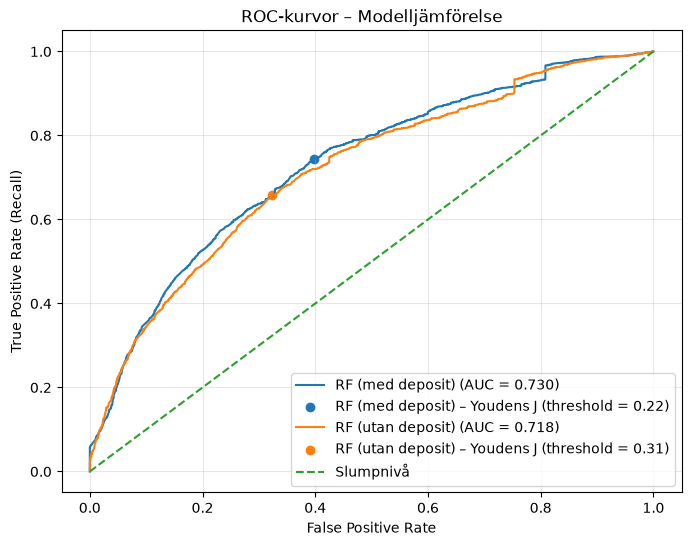

In [10]:
# plot_roc_curve tar en dictionary med modellnamn och tillhörande sannolikheter
roc_results = plot_roc_curve(
    y_val,
    {
        "RF (med deposit)": probas_full,
        "RF (utan deposit)": probas_no_dep
    }
)

# Spara figuren högupplöst till mappen outputs/figures/
save_plot("rf_val_deposit_comparison_roc.png")

#### Feature Importances (vilka variabler väger tyngst?)

In [11]:
# Hämta namnen på alla transformerade kolumner från preprocessorn
feature_names = preprocessor_full.get_feature_names_out()

# Hämta och sortera feature importances fallande
df_importance = get_feature_importances(rf_full, feature_names)

print("Topp 15 viktigaste features i Random Forest:")
display(df_importance.head(15))

Topp 15 viktigaste features i Random Forest:


,feature,importance
0,cat__deposit_type_Non Refund,0.245335
1,cat__deposit_type_No Deposit,0.187124
2,num__previous_cancellations,0.118121
3,num__lead_time,0.114075
4,cat__market_segment_Groups,0.031535
5,cat__customer_type_Transient,0.030415
6,cat__customer_type_Transient-Party,0.028129
7,agent__agent_9,0.015756
8,cat__market_segment_Online TA,0.015665
9,cat__market_segment_Offline TA/TO,0.011371


#### Visa Leaderboard

In [12]:
# Visa sammanställning av alla loggade körningar
leaderboard = get_leaderboard()
display(leaderboard)

,timestamp,model,feature_set,dataset,precision_at_20,recall_at_20,f1_score,antal_flaggade,korrekt_flaggade,notes
0,2026-10-15 11:04,Random Forest,med deposit_type,val,0.6466,0.3667,0.4680,2329,1506,"n_estimators=100, max_depth=15"
1,2026-10-15 11:22,Random Forest,med deposit_type,val,0.6466,0.3667,0.4680,2329,1506,"n_estimators=100, max_depth=15"
2,2026-10-15 11:04,Random Forest,utan deposit_type,val,0.6385,0.3621,0.4621,2329,1487,"n_estimators=100, max_depth=15"
3,2026-10-15 11:22,Random Forest,utan deposit_type,val,0.6385,0.3621,0.4621,2329,1487,"n_estimators=100, max_depth=15"
